In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

# load the pharmacy sales dataset
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

# clean and prepare the required columns
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["units_sold"] = pd.to_numeric(df["units_sold"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["covid_flag"] = pd.to_numeric(df["covid_flag"], errors="coerce")

df = df.dropna(
    subset=["date", "units_sold", "unit_price", "covid_flag"]
).copy()

df = df[
    (df["units_sold"] >= 0) &
    (df["unit_price"] > 0) &
    (df["covid_flag"].isin([0, 1]))
].copy()

# create the sales revenue feature
df["sales_revenue"] = df["units_sold"] * df["unit_price"]

print("dataset shape:", df.shape)
print(df.head())
print("missing values:\n", df.isnull().sum())

g++ not available, if using conda: `conda install gxx`


dataset shape: (177990, 15)
        date  year  month  day         region    country category    medicine  \
0 2025-10-12  2025     10   12    Middle East        UAE  Chronic  Amlodipine   
1 2020-09-15  2020      9   15     South Asia      India  Chronic  Amlodipine   
2 2020-02-26  2020      2   26    Middle East        UAE  Vitamin   Vitamin C   
3 2025-11-09  2025     11    9     South Asia  Sri Lanka  Chronic  Amlodipine   
4 2022-04-04  2022      4    4  South America  Argentina  Chronic  Amlodipine   

  age_group  units_sold  unit_price  stock_level  expiry_days_remaining  \
0      0-12         328       45.38         4774                    466   
1     26-45         371       75.49         4584                    181   
2      0-12         948       22.51         3934                    556   
3      0-12         275       63.29         4544                    330   
4     26-45         563       44.28         4284                    590   

   covid_flag  sales_revenue  
0  

In [2]:
# select the variables used in the model
features = df[["units_sold", "unit_price", "covid_flag"]].copy()

# standardize the target and price feature
target_mean = features["units_sold"].mean()
target_std = features["units_sold"].std()

price_mean = features["unit_price"].mean()
price_std = features["unit_price"].std()

features["sales_scaled"] = (
    features["units_sold"] - target_mean
) / target_std

features["price_scaled"] = (
    features["unit_price"] - price_mean
) / price_std

# select a reproducible sample for efficient mcmc computation
sample = features.sample(
    n=min(5000, len(features)),
    random_state=42
)

print("selected observations:", len(sample))
print(sample.head())

selected observations: 5000
        units_sold  unit_price  covid_flag  sales_scaled  price_scaled
168929         211       53.07           0     -0.699017      0.018790
20669          312       79.53           0     -0.401015      0.983712
4526           514       49.82           0      0.194988     -0.099728
171149         199       64.46           1     -0.734423      0.434152
65989          401       87.59           0     -0.138420      1.277638


In [4]:

# define the bayesian regression model
with pm.Model() as bayesian_model:

    # define prior distributions for model coefficients
    intercept = pm.Normal("intercept", mu=0, sigma=1)
    beta_price = pm.Normal("beta_price", mu=0, sigma=1)
    beta_covid = pm.Normal("beta_covid", mu=0, sigma=1)

    # define a positive prior for residual variation
    sigma = pm.HalfNormal("sigma", sigma=1)

    # calculate expected standardized sales
    mu = (
        intercept
        + beta_price * sample["price_scaled"].values
        + beta_covid * sample["covid_flag"].values
    )

    # define the likelihood using observed sales
    likelihood = pm.Normal(
        "likelihood",
        mu=mu,
        sigma=sigma,
        observed=sample["sales_scaled"].values
    )

    # generate samples from the prior predictive distribution
    prior_predictive = pm.sample_prior_predictive(
        draws=500,
        random_seed=42
    )

print("prior distributions and likelihood defined")


Sampling: [beta_covid, beta_price, intercept, likelihood, sigma]


prior distributions and likelihood defined


In [5]:
# estimate posterior distributions using mcmc
with bayesian_model:
    trace = pm.sample(
        draws=1500,
        tune=1500,
        chains=4,
        cores=1,
        target_accept=0.95,
        random_seed=42,
        return_inferencedata=True
    )

print("mcmc sampling completed")

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [intercept, beta_price, beta_covid, sigma]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 8 seconds.


mcmc sampling completed


In [9]:
# calculate posterior estimates and 95% credible intervals
summary = az.summary(
    trace,
    var_names=["intercept", "beta_price", "beta_covid", "sigma"],
    ci_prob=0.95,
    round_to=4
)

# display posterior estimates and credible intervals
print("posterior estimates with 95% credible intervals")
print(summary)


posterior estimates with 95% credible intervals
              mean      sd  eti95_lb  eti95_ub   ess_bulk   ess_tail   r_hat  \
intercept  -0.2125  0.0174   -0.2459   -0.1777  3888.1145  3957.6317  1.0001   
beta_price  0.0076  0.0139   -0.0200    0.0350  6041.1575  4040.5227  1.0012   
beta_covid  0.6658  0.0302    0.6072    0.7250  3771.1821  3806.8010  1.0017   
sigma       0.9902  0.0101    0.9705    1.0101  6601.7303  4019.9550  1.0012   

            mcse_mean  mcse_sd  
intercept      0.0003   0.0002  
beta_price     0.0002   0.0002  
beta_covid     0.0005   0.0004  
sigma          0.0001   0.0001  


In [10]:
# extract posterior samples for model coefficients
price_effect = trace.posterior["beta_price"].values.flatten()
covid_effect = trace.posterior["beta_covid"].values.flatten()

# calculate posterior probabilities for decision-making
prob_price_negative = np.mean(price_effect < 0)
prob_covid_positive = np.mean(covid_effect > 0)

# convert standardized effects to units sold
price_effect_units = price_effect * target_std / price_std
covid_effect_units = covid_effect * target_std

# calculate 95% credible intervals
price_ci = np.quantile(price_effect_units, [0.025, 0.975])
covid_ci = np.quantile(covid_effect_units, [0.025, 0.975])

print("price effect on units sold per one-unit price increase")
print("posterior mean:", round(price_effect_units.mean(), 3))
print("95% credible interval:", np.round(price_ci, 3))
print("probability of a negative price effect:",
      round(prob_price_negative, 4))

print("\ncovid effect on units sold")
print("posterior mean:", round(covid_effect_units.mean(), 3))
print("95% credible interval:", np.round(covid_ci, 3))
print("probability of a positive covid effect:",
      round(prob_covid_positive, 4))

price effect on units sold per one-unit price increase
posterior mean: 0.094
95% credible interval: [-0.247  0.432]
probability of a negative price effect: 0.2935

covid effect on units sold
posterior mean: 225.664
95% credible interval: [205.788 245.71 ]
probability of a positive covid effect: 1.0


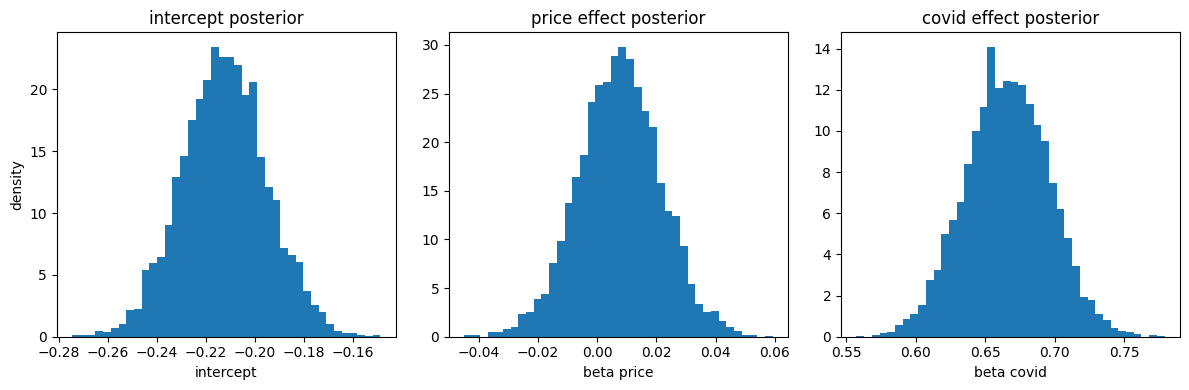

intercept: 95% credible interval = (-0.2459, -0.1777)
price effect: 95% credible interval = (-0.0200, 0.0350)
covid effect: 95% credible interval = (0.6072, 0.7250)


In [12]:

# visualize posterior distributions and 95% credible intervals

# extract posterior samples
intercept_samples = trace.posterior["intercept"].values.flatten()
price_samples = trace.posterior["beta_price"].values.flatten()
covid_samples = trace.posterior["beta_covid"].values.flatten()

# create plots for posterior distributions
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(intercept_samples, bins=40, density=True)
plt.title("intercept posterior")
plt.xlabel("intercept")
plt.ylabel("density")

plt.subplot(1, 3, 2)
plt.hist(price_samples, bins=40, density=True)
plt.title("price effect posterior")
plt.xlabel("beta price")

plt.subplot(1, 3, 3)
plt.hist(covid_samples, bins=40, density=True)
plt.title("covid effect posterior")
plt.xlabel("beta covid")

plt.tight_layout()
plt.show()

# calculate and print 95% credible intervals
for name, values in [
    ("intercept", intercept_samples),
    ("price effect", price_samples),
    ("covid effect", covid_samples)
]:
    lower, upper = np.quantile(values, [0.025, 0.975])
    print(f"{name}: 95% credible interval = ({lower:.4f}, {upper:.4f})")


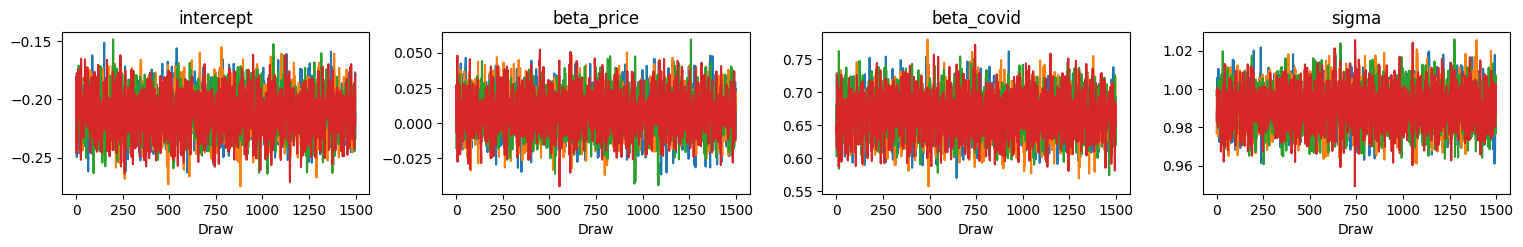

mcmc convergence diagnostics
            r_hat  ess_bulk  ess_tail
intercept   1.000  3888.115  3957.632
beta_price  1.001  6041.158  4040.523
beta_covid  1.002  3771.182  3806.801
sigma       1.001  6601.730  4019.955

parameters with r-hat above 1.01:
Empty DataFrame
Columns: [mean, sd, eti89_lb, eti89_ub, ess_bulk, ess_tail, r_hat, mcse_mean, mcse_sd]
Index: []


In [13]:
# inspect trace plots for sampling stability
az.plot_trace(
    trace,
    var_names=["intercept", "beta_price", "beta_covid", "sigma"]
)

plt.tight_layout()
plt.show()

# calculate convergence diagnostics
diagnostics = az.summary(trace, round_to=3)

print("mcmc convergence diagnostics")
print(diagnostics[["r_hat", "ess_bulk", "ess_tail"]])

# flag parameters with possible convergence problems
print("\nparameters with r-hat above 1.01:")
print(diagnostics[diagnostics["r_hat"] > 1.01])

Sampling: [likelihood]


Output()

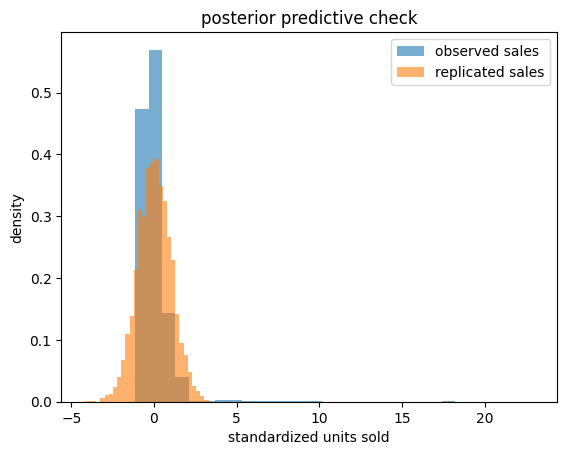

In [14]:
# generate replicated sales observations from the fitted model
with bayesian_model:
    posterior_predictive = pm.sample_posterior_predictive(
        trace,
        var_names=["likelihood"],
        random_seed=42
    )

# plot observed and replicated sales distributions
observed_sales = sample["sales_scaled"].values
predicted_sales = (
    posterior_predictive.posterior_predictive["likelihood"]
    .values.reshape(-1, len(sample))
)

plt.hist(observed_sales, bins=30, density=True,
         alpha=0.6, label="observed sales")

plt.hist(predicted_sales[0], bins=30, density=True,
         alpha=0.6, label="replicated sales")

plt.xlabel("standardized units sold")
plt.ylabel("density")
plt.title("posterior predictive check")
plt.legend()
plt.show()

In [15]:
# interpret the estimated effects using posterior probabilities
print("bayesian decision-making report")

if prob_price_negative >= 0.95:
    print("strong evidence of a negative price-sales association")
elif prob_price_negative <= 0.05:
    print("strong evidence of a positive price-sales association")
else:
    print("price-sales association remains uncertain")

if prob_covid_positive >= 0.95:
    print("strong evidence of a positive covid-sales association")
elif prob_covid_positive <= 0.05:
    print("strong evidence of a negative covid-sales association")
else:
    print("covid-sales association remains uncertain")

print("\nprice effect 95% credible interval:", np.round(price_ci, 3))
print("covid effect 95% credible interval:", np.round(covid_ci, 3))

bayesian decision-making report
price-sales association remains uncertain
strong evidence of a positive covid-sales association

price effect 95% credible interval: [-0.247  0.432]
covid effect 95% credible interval: [205.788 245.71 ]
